# 01 — Telemetry exploratory analysis (NAB CloudWatch CPU)

Capstone: **Intelligent Incident Detection for SaaS Platforms Using OpenTelemetry and Machine Learning** (UC Berkeley AI/ML).

This notebook prepares one public benchmark series for later anomaly-detection experiments:

1. Download the Numenta Anomaly Benchmark (NAB) series and its window labels.
2. Parse timestamps and mark observations that fall inside the annotated windows.
3. Summarize missingness, sampling cadence, and the value distribution.
4. Plot the series with the annotated windows overlaid.
5. Build causal features from the current observation and earlier observations only.
6. Save the processed table for downstream notebooks.

Later modeling should use a **chronological** train/validation/test split. Do not shuffle rows. Do not fit scalers on future data. The column `is_anomaly` is an evaluation label, not a model input.

## What this data is — and what it is not

The file `ec2_cpu_utilization_5f5533.csv` is an **Amazon CloudWatch** metric published in the Numenta Anomaly Benchmark (`realAWSCloudwatch`). It is EC2 CPU utilization sampled about every five minutes. NAB also publishes hand-annotated anomaly **windows** in `combined_windows.json`.

This is **not** native OpenTelemetry data. It has no traces, spans, resource attributes, or exemplars. It is **not** a log of verified SaaS customer incidents, and the windows are **not** confirmed root causes. NAB windows are wide intervals drawn around unusual metric behavior so scoring can credit a detector that fires inside the interval. A point inside a window is “inside an annotated window,” not a diagnosed production incident.

We use the series only as a public, time-ordered univariate baseline while the project’s own OpenTelemetry pipeline is built.

## Setup

Paths are resolved from the repository root so the notebook works whether the kernel starts in `notebooks/` or at the repo root. Downloads are written under `data/raw/nab/`. Those files are gitignored.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns

sns.set_theme(style="whitegrid")

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "data").exists() and (REPO_ROOT.parent / "data").exists():
    REPO_ROOT = REPO_ROOT.parent

RAW_DIR = REPO_ROOT / "data" / "raw" / "nab"
PROCESSED_DIR = REPO_ROOT / "data" / "processed"
CPU_PATH = RAW_DIR / "cpu.csv"
WINDOWS_PATH = RAW_DIR / "anomaly_windows.json"
FEATURES_PATH = PROCESSED_DIR / "nab_cpu_features.csv"

CPU_URL = (
    "https://raw.githubusercontent.com/numenta/NAB/master/data/"
    "realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv"
)
WINDOWS_URL = (
    "https://raw.githubusercontent.com/numenta/NAB/master/labels/combined_windows.json"
)
NAB_KEY = "realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv"

# 12 samples at a 5-minute cadence is about one hour of history.
ROLLING_WINDOW = 12
LAGS = (1, 2, 3)
FEATURE_COLUMNS = [
    "value",
    "roll_mean_12",
    "roll_std_12",
    "diff_1",
    "lag_1",
    "lag_2",
    "lag_3",
]

print("repo:", REPO_ROOT)
print("pandas", pd.__version__, "| numpy", np.__version__)

repo: C:\Users\rvmkr\saas-aiops-observability
pandas 3.1.1 | numpy 2.5.5


## Download

The cell below fetches both files from the NAB GitHub repository. A failed download raises an exception; nothing below invents a series if the request fails.

In [2]:
def download(url: str, dest: Path) -> None:
    dest.parent.mkdir(parents=True, exist_ok=True)
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    dest.write_bytes(response.content)
    print(f"saved {dest.relative_to(REPO_ROOT)} ({dest.stat().st_size:,} bytes)")


download(CPU_URL, CPU_PATH)
download(WINDOWS_URL, WINDOWS_PATH)

cpu_head = CPU_PATH.read_text(encoding="utf-8").splitlines()[0]
if cpu_head.strip() != "timestamp,value":
    raise ValueError(f"Unexpected CSV header: {cpu_head!r}")
print("CSV header:", cpu_head)

saved data\raw\nab\cpu.csv (119,229 bytes)
saved data\raw\nab\anomaly_windows.json (15,359 bytes)
CSV header: timestamp,value


## Load the metric and the window labels

Timestamps stay timezone-naive, matching the NAB files. An observation is labeled `is_anomaly=True` when its timestamp lies inside any window for `realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv`, including both endpoints. Rows are sorted by time before any feature is computed.

In [3]:
cpu = pd.read_csv(CPU_PATH)
expected_columns = {"timestamp", "value"}
if set(cpu.columns) != expected_columns:
    raise ValueError(f"Unexpected columns: {list(cpu.columns)}")

cpu["timestamp"] = pd.to_datetime(cpu["timestamp"], format="%Y-%m-%d %H:%M:%S")
cpu["value"] = pd.to_numeric(cpu["value"], errors="coerce")
cpu = cpu.sort_values("timestamp").reset_index(drop=True)

if not cpu["timestamp"].is_monotonic_increasing:
    raise ValueError("Timestamps are not strictly chronological after sorting.")
if cpu["timestamp"].duplicated().any():
    raise ValueError("Duplicate timestamps found; refusing to build a single series.")

windows_json = pd.read_json(WINDOWS_PATH, typ="series")
if NAB_KEY not in windows_json.index:
    raise KeyError(f"{NAB_KEY} not found in {WINDOWS_PATH.name}")

windows = []
for start_raw, end_raw in windows_json[NAB_KEY]:
    start = pd.Timestamp(start_raw)
    end = pd.Timestamp(end_raw)
    if end < start:
        raise ValueError(f"Window end before start: {start} .. {end}")
    windows.append((start, end))

cpu["is_anomaly"] = False
for start, end in windows:
    inside = (cpu["timestamp"] >= start) & (cpu["timestamp"] <= end)
    cpu.loc[inside, "is_anomaly"] = True

print(f"rows: {len(cpu):,}")
print(f"range: {cpu['timestamp'].iloc[0]}  ->  {cpu['timestamp'].iloc[-1]}")
print(f"annotated windows for {NAB_KEY}: {len(windows)}")
for start, end in windows:
    n_inside = int(((cpu['timestamp'] >= start) & (cpu['timestamp'] <= end)).sum())
    print(f"  {start}  ->  {end}  ({n_inside} observations)")
print(f"observations inside a window: {int(cpu['is_anomaly'].sum()):,} "
      f"({cpu['is_anomaly'].mean():.1%})")
cpu.head()

rows: 4,032
range: 2014-02-14 14:27:00  ->  2014-02-28 14:22:00
annotated windows for realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv: 2
  2014-02-18 16:02:00  ->  2014-02-19 08:42:00  (201 observations)
  2014-02-24 10:17:00  ->  2014-02-25 02:57:00  (201 observations)
observations inside a window: 402 (10.0%)


,timestamp,value,is_anomaly
0,2014-02-14 14:27:00,51.846,False
1,2014-02-14 14:32:00,44.508,False
2,2014-02-14 14:37:00,41.244,False
3,2014-02-14 14:42:00,48.568,False
4,2014-02-14 14:47:00,46.714,False


## Missing values, cadence, and distribution

CloudWatch’s standard period for this NAB file is five minutes. The checks below report the actual spacing, including any gaps, instead of assuming the file is perfectly regular. Summary statistics describe the CPU values; they are not incident rates.

In [4]:
missing = cpu.isna().sum()
print("Missing values")
print(missing.to_string())
print()

deltas = cpu["timestamp"].diff().dropna()
print("Spacing value counts (top)")
print(deltas.value_counts().head().to_string())
print()
print("median spacing:", deltas.median())
print("min spacing:   ", deltas.min())
print("max spacing:   ", deltas.max())

expected = pd.Timedelta(minutes=5)
gaps = deltas[deltas > expected]
print(f"gaps longer than {expected}: {len(gaps)}")
if len(gaps):
    print(gaps.describe())
if deltas.median() != expected:
    print(f"WARNING: median spacing is {deltas.median()}, not {expected}.")
else:
    print("Median spacing matches the 5-minute CloudWatch period.")

print()
print(cpu["value"].describe().to_string())

Missing values
timestamp     0
value         0
is_anomaly    0

Spacing value counts (top)
timestamp
0 days 00:05:00    4031

median spacing: 0 days 00:05:00
min spacing:    0 days 00:05:00
max spacing:    0 days 00:05:00
gaps longer than 0 days 00:05:00: 0
Median spacing matches the 5-minute CloudWatch period.

count    4032.000000
mean       43.110372
std         4.303565
min        34.766000
25%        39.296000
50%        42.918000
75%        46.006000
max        68.092000


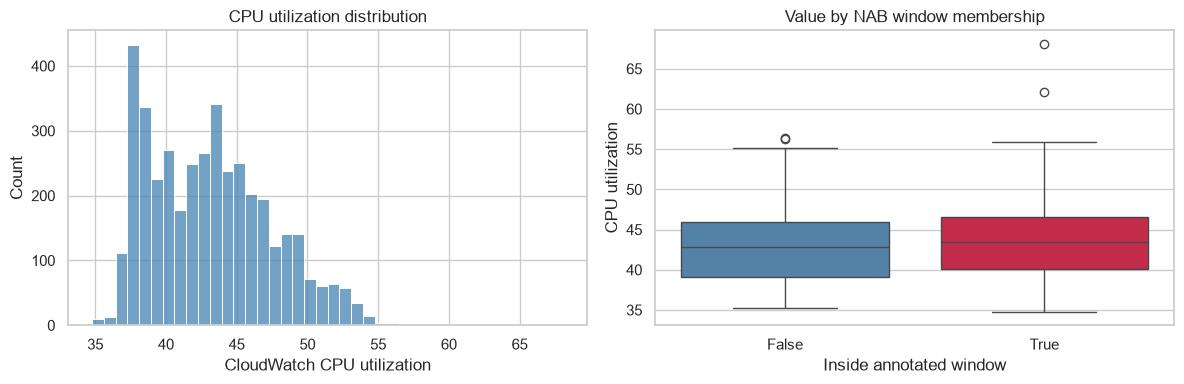

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=cpu, x="value", bins=40, ax=axes[0], color="steelblue")
axes[0].set_title("CPU utilization distribution")
axes[0].set_xlabel("CloudWatch CPU utilization")

sns.boxplot(
    data=cpu,
    x="is_anomaly",
    y="value",
    hue="is_anomaly",
    ax=axes[1],
    palette={False: "steelblue", True: "crimson"},
    legend=False,
)
axes[1].set_title("Value by NAB window membership")
axes[1].set_xlabel("Inside annotated window")
axes[1].set_ylabel("CPU utilization")

fig.tight_layout()
plt.show()

## Time series and annotated windows

Shaded bands are the NAB windows. On the full series, red points mark observations inside those bands. The zoomed panels draw the same interval as a crimson line. The windows are many hours long, so most samples inside them look like ordinary CPU readings; the annotation marks an interval, not every point as a distinct failure.

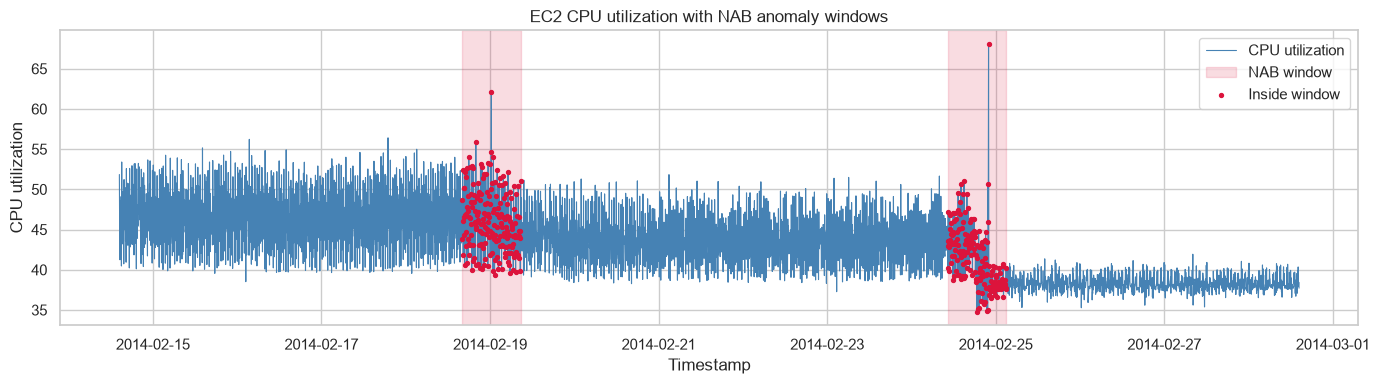

In [6]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(
    cpu["timestamp"],
    cpu["value"],
    color="steelblue",
    linewidth=0.8,
    label="CPU utilization",
)
for i, (start, end) in enumerate(windows):
    ax.axvspan(
        start,
        end,
        color="crimson",
        alpha=0.15,
        label="NAB window" if i == 0 else None,
    )
inside = cpu.loc[cpu["is_anomaly"]]
ax.scatter(
    inside["timestamp"],
    inside["value"],
    s=8,
    color="crimson",
    zorder=3,
    label="Inside window",
)
ax.set_title("EC2 CPU utilization with NAB anomaly windows")
ax.set_xlabel("Timestamp")
ax.set_ylabel("CPU utilization")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

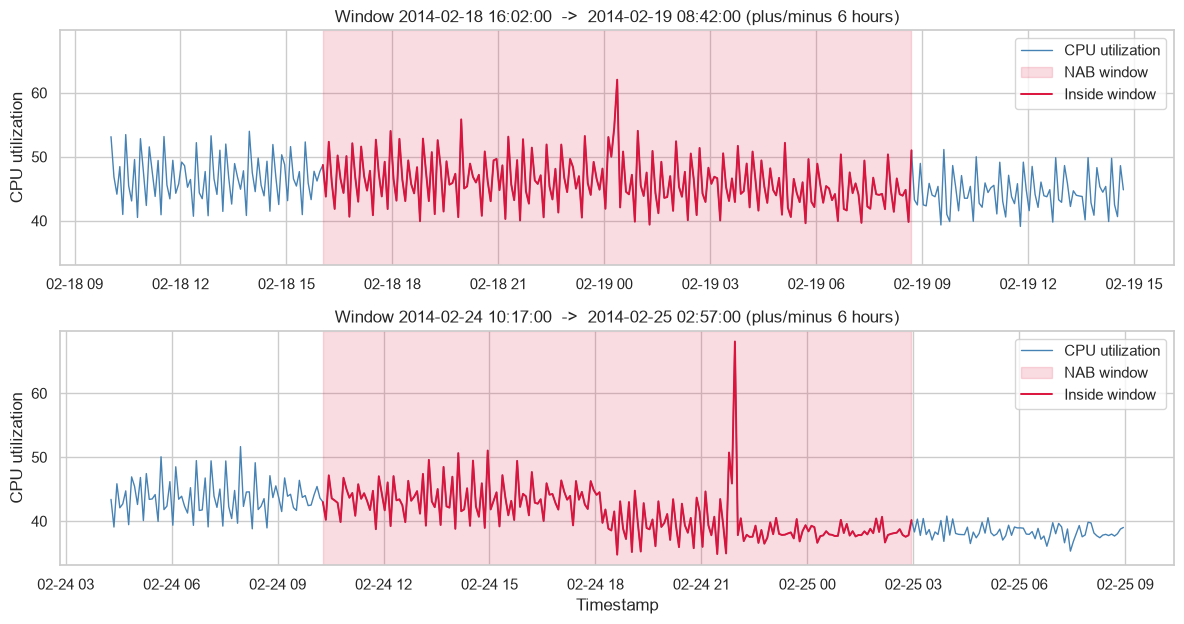

In [7]:
n_windows = len(windows)
fig, axes = plt.subplots(n_windows, 1, figsize=(12, 3.2 * n_windows), sharey=True)
if n_windows == 1:
    axes = [axes]

pad = pd.Timedelta(hours=6)
for ax, (start, end) in zip(axes, windows):
    view = cpu[(cpu["timestamp"] >= start - pad) & (cpu["timestamp"] <= end + pad)]
    ax.plot(view["timestamp"], view["value"], color="steelblue", linewidth=1.0, label="CPU utilization")
    ax.axvspan(start, end, color="crimson", alpha=0.15, label="NAB window")
    flagged = view.loc[view["is_anomaly"]]
    ax.plot(flagged["timestamp"], flagged["value"], color="crimson", linewidth=1.4, label="Inside window")
    ax.legend(loc="upper right")
    ax.set_title(f"Window {start}  ->  {end} (plus/minus 6 hours)")
    ax.set_ylabel("CPU utilization")

axes[-1].set_xlabel("Timestamp")
fig.tight_layout()
plt.show()

## Causal features

Every feature at time *t* uses `value[t]` and earlier values only:

| Column | Definition |
| --- | --- |
| `roll_mean_12` | Mean of the current point and the previous 11 points |
| `roll_std_12` | Sample standard deviation over that same trailing window |
| `diff_1` | `value[t] - value[t-1]` |
| `lag_1`, `lag_2`, `lag_3` | `value[t-1]`, `value[t-2]`, `value[t-3]` |

Pandas rolling windows are right-aligned (`center=False`), so they do not look ahead. The first rows are null until a full window or lag exists. Those rows are kept in the file and should be dropped before modeling. Do not backfill them from later observations.

`is_anomaly` is stored beside the features so a later notebook can score detections. It is excluded from `FEATURE_COLUMNS` and must not be passed to a detector as an input. A chronological split — training only on earlier timestamps — is required when those models are fit. Random splits would leak the level and variance of future traffic into training.

In [8]:
def causal_features(values: pd.Series) -> pd.DataFrame:
    """Trailing features. `values` must already be in chronological order."""
    frame = pd.DataFrame(index=values.index)
    trailing = values.rolling(ROLLING_WINDOW, min_periods=ROLLING_WINDOW, center=False)
    frame["roll_mean_12"] = trailing.mean()
    frame["roll_std_12"] = trailing.std()
    frame["diff_1"] = values.diff(1)
    for lag in LAGS:
        frame[f"lag_{lag}"] = values.shift(lag)
    return frame


features = causal_features(cpu["value"])
model_frame = pd.concat(
    [cpu[["timestamp", "value", "is_anomaly"]], features],
    axis=1,
)

if list(model_frame["timestamp"]) != sorted(model_frame["timestamp"]):
    raise ValueError("Processed frame is not in chronological order.")
if "is_anomaly" in FEATURE_COLUMNS:
    raise ValueError("Anomaly labels must not be model input features.")
missing_features = [name for name in FEATURE_COLUMNS if name not in model_frame.columns]
if missing_features:
    raise ValueError(f"Missing feature columns: {missing_features}")

# A feature at time t must match the feature computed from the prefix ending at t.
prefix = min(200, len(cpu))
prefix_features = causal_features(cpu["value"].iloc[:prefix])
pd.testing.assert_frame_equal(
    features.iloc[:prefix].reset_index(drop=True),
    prefix_features.reset_index(drop=True),
    check_dtype=False,
)
print(f"Causal check passed on the first {prefix} rows.")

print("Nulls introduced by the warm-up (lags and the 12-point window):")
print(model_frame[FEATURE_COLUMNS].isna().sum().to_string())
print()
print("Input features for later models:", FEATURE_COLUMNS)
print("Label column (evaluation only): is_anomaly")
model_frame.head(15)

Causal check passed on the first 200 rows.
Nulls introduced by the warm-up (lags and the 12-point window):
value            0
roll_mean_12    11
roll_std_12     11
diff_1           1
lag_1            1
lag_2            2
lag_3            3

Input features for later models: ['value', 'roll_mean_12', 'roll_std_12', 'diff_1', 'lag_1', 'lag_2', 'lag_3']
Label column (evaluation only): is_anomaly


,timestamp,value,is_anomaly,roll_mean_12,roll_std_12,diff_1,lag_1,lag_2,lag_3
0,2014-02-14 14:27:00,51.846,False,NaN,NaN,NaN,NaN,NaN,NaN
1,2014-02-14 14:32:00,44.508,False,NaN,NaN,-7.338,51.846,NaN,NaN
2,2014-02-14 14:37:00,41.244,False,NaN,NaN,-3.264,44.508,51.846,NaN
3,2014-02-14 14:42:00,48.568,False,NaN,NaN,7.324,41.244,44.508,51.846
4,2014-02-14 14:47:00,46.714,False,NaN,NaN,-1.854,48.568,41.244,44.508
5,2014-02-14 14:52:00,44.986,False,NaN,NaN,-1.728,46.714,48.568,41.244
6,2014-02-14 14:57:00,49.108,False,NaN,NaN,4.122,44.986,46.714,48.568
7,2014-02-14 15:02:00,40.470,False,NaN,NaN,-8.638,49.108,44.986,46.714
8,2014-02-14 15:07:00,53.404,False,NaN,NaN,12.934,40.470,49.108,44.986
9,2014-02-14 15:12:00,45.400,False,NaN,NaN,-8.004,53.404,40.470,49.108


DAY 2 — DATASET SUMMARY
Total observations: 4032
Start timestamp: 2014-02-14 14:27:00
End timestamp: 2014-02-28 14:22:00
Missing values:
timestamp    0
value        0
dtype: int64
Duplicate timestamps: 0
Median sampling interval: 0 days 00:05:00

CPU utilization statistics:
count    4032.000000
mean       43.110372
std         4.303565
min        34.766000
25%        39.296000
50%        42.918000
75%        46.006000
max        68.092000
Name: value, dtype: float64

ANOMALY LABEL DISTRIBUTION
Normal observations: 3630
Anomalous observations: 402
Anomaly percentage: 9.97
Number of annotated windows: 2


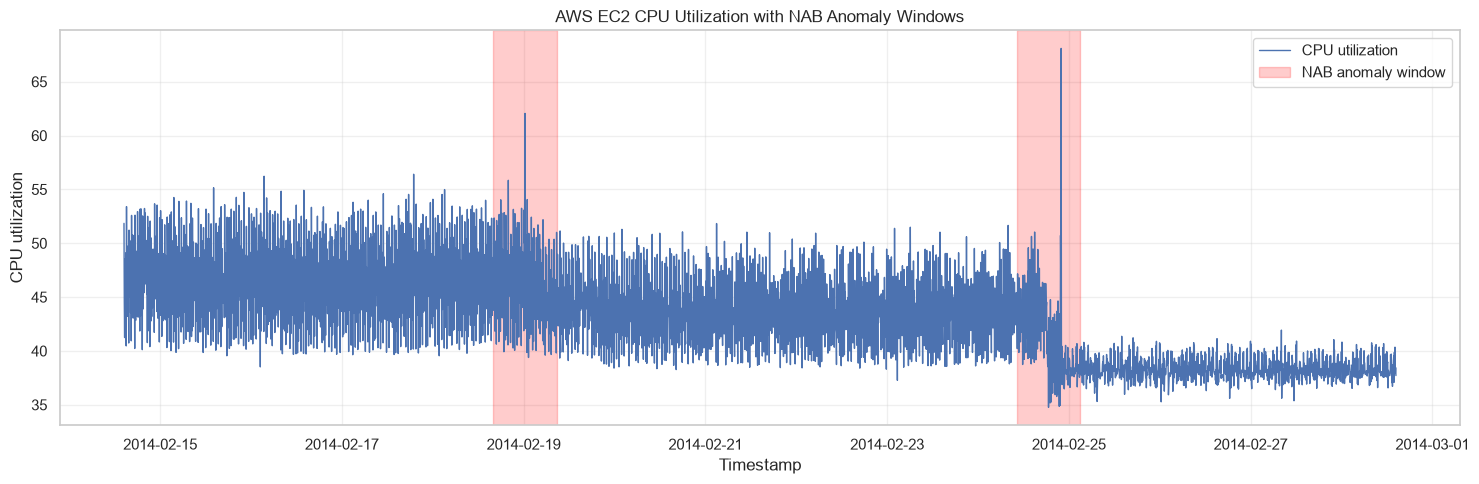

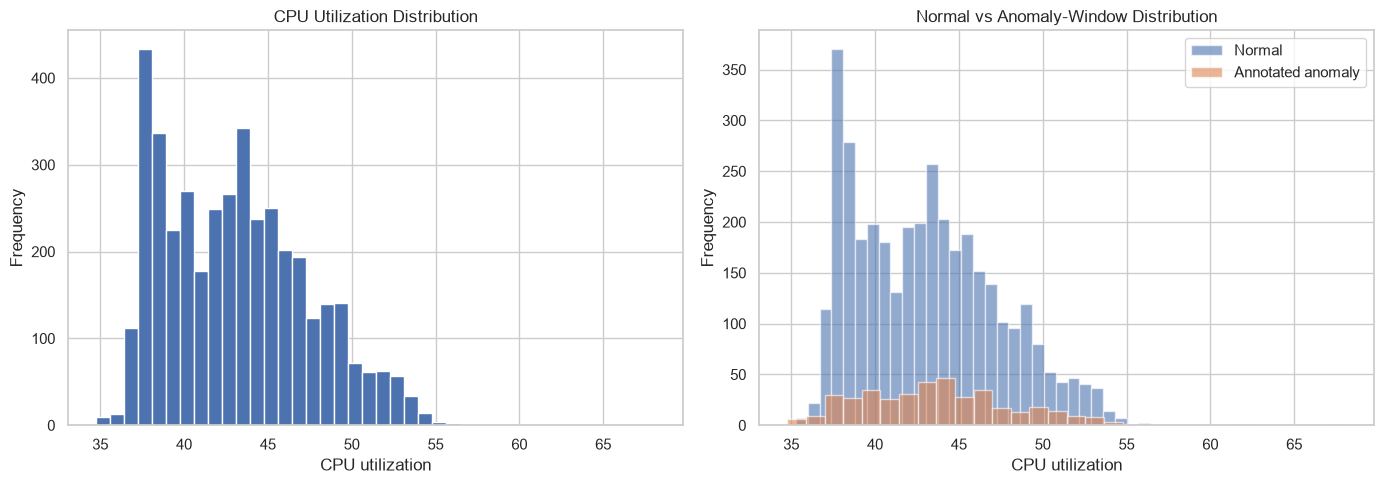

C:\Users\rvmkr\AppData\Local\Temp\ipykernel_46928\1129939225.py:175: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["timestamp"].dt.dayofweek



FEATURE ENGINEERING
Feature columns: ['value', 'rolling_mean_12', 'rolling_std_12', 'change_rate', 'lag_1', 'lag_3', 'lag_6', 'hour', 'day_of_week']

Missing feature values:
value               0
rolling_mean_12    11
rolling_std_12     11
change_rate         1
lag_1               1
lag_3               3
lag_6               6
hour                0
day_of_week         0
dtype: int64

Observations after feature preparation: 4021


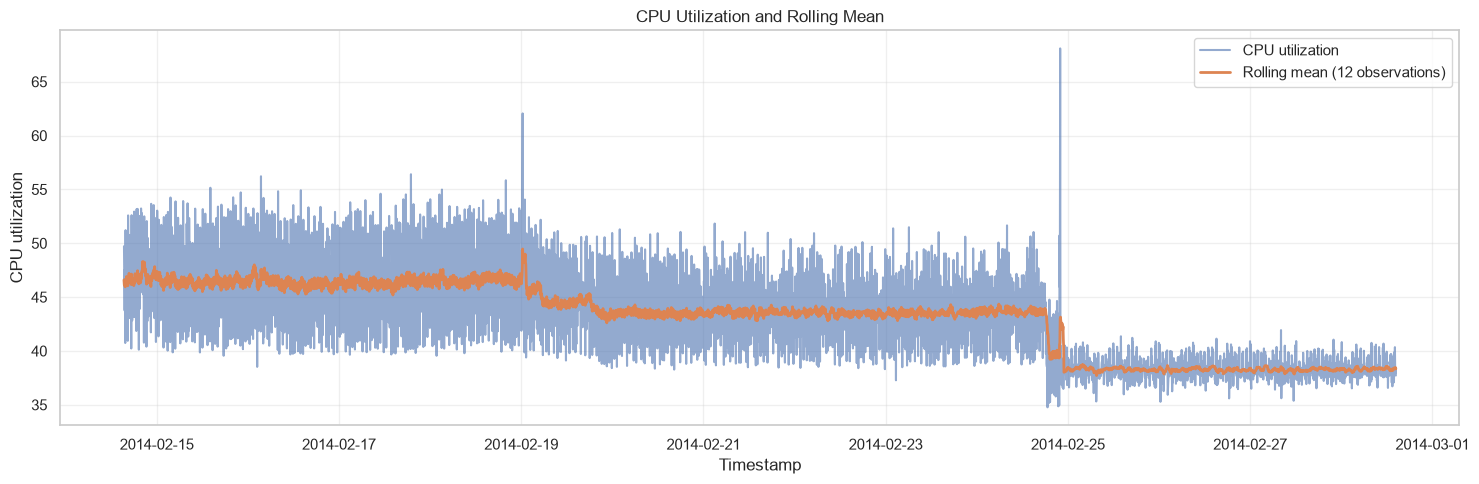


CHRONOLOGICAL DATA SPLITS

TRAIN
Observations: 2814
Normal: 2613
Anomalies: 201
Anomaly percentage: 7.14
Start: 2014-02-14 15:22:00
End: 2014-02-24 09:47:00

VALIDATION
Observations: 603
Normal: 402
Anomalies: 201
Anomaly percentage: 33.33
Start: 2014-02-24 09:52:00
End: 2014-02-26 12:02:00

TEST
Observations: 604
Normal: 604
Anomalies: 0
Anomaly percentage: 0.0
Start: 2014-02-26 12:07:00
End: 2014-02-28 14:22:00

Processed datasets saved to: C:\Users\rvmkr\saas-aiops-observability\data\processed

ML READINESS ASSESSMENT

Important methodological notes:
- NAB is AWS CloudWatch data, not native OpenTelemetry.
- Annotation windows are not exact outage timestamps.
- No future observations were used in rolling features.
- No random shuffle was used.
- Labels are excluded from model input features.
- Model training and scaling will occur on Day 3.

DAY 2 ANALYSIS COMPLETE


In [10]:

# ============================================================
# UC Berkeley AI/ML Capstone — Day 2
# SaaS AIOps: Exploratory Data Analysis & ML Preparation
# Source: Numenta Anomaly Benchmark (NAB)
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Locate project and load original NAB data
# ------------------------------------------------------------

root = Path.cwd().resolve()

if not (root / "data").exists():
    root = root.parent

raw_path = root / "data/raw/nab/cpu.csv"
labels_path = root / "data/raw/nab/anomaly_windows.json"
output_dir = root / "data/processed"
output_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(raw_path)

required_columns = {"timestamp", "value"}
assert required_columns.issubset(df.columns), (
    f"Missing columns: {required_columns - set(df.columns)}"
)

df["timestamp"] = pd.to_datetime(df["timestamp"], errors="raise")
df["value"] = pd.to_numeric(df["value"], errors="coerce")

df = df.sort_values("timestamp").reset_index(drop=True)

print("=" * 65)
print("DAY 2 — DATASET SUMMARY")
print("=" * 65)

print("Total observations:", len(df))
print("Start timestamp:", df["timestamp"].min())
print("End timestamp:", df["timestamp"].max())
print("Missing values:")
print(df.isna().sum())
print("Duplicate timestamps:", df["timestamp"].duplicated().sum())

intervals = df["timestamp"].diff().dropna()

if len(intervals):
    print("Median sampling interval:", intervals.median())

print("\nCPU utilization statistics:")
print(df["value"].describe())

# ------------------------------------------------------------
# 2. Load NAB annotated anomaly windows
# ------------------------------------------------------------

with open(labels_path, "r", encoding="utf-8") as f:
    windows = json.load(f)

dataset_key = "realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv"

if dataset_key not in windows:
    raise KeyError(f"Dataset key not found: {dataset_key}")

anomaly_windows = [
    (pd.Timestamp(start), pd.Timestamp(end))
    for start, end in windows[dataset_key]
]

df["anomaly_label"] = 0

for start, end in anomaly_windows:
    mask = df["timestamp"].between(start, end)
    df.loc[mask, "anomaly_label"] = 1

print("\n" + "=" * 65)
print("ANOMALY LABEL DISTRIBUTION")
print("=" * 65)

counts = df["anomaly_label"].value_counts().reindex(
    [0, 1], fill_value=0
)

print("Normal observations:", counts[0])
print("Anomalous observations:", counts[1])
print("Anomaly percentage:", round(100 * counts[1] / len(df), 2))
print("Number of annotated windows:", len(anomaly_windows))

# ------------------------------------------------------------
# 3. Plot CPU utilization with anomaly windows
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    df["timestamp"],
    df["value"],
    label="CPU utilization",
    linewidth=1
)

for i, (start, end) in enumerate(anomaly_windows):
    ax.axvspan(
        start,
        end,
        color="red",
        alpha=0.2,
        label="NAB anomaly window" if i == 0 else None
    )

ax.set_title("AWS EC2 CPU Utilization with NAB Anomaly Windows")
ax.set_xlabel("Timestamp")
ax.set_ylabel("CPU utilization")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. CPU utilization distribution
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df["value"].dropna(), bins=40)
axes[0].set_title("CPU Utilization Distribution")
axes[0].set_xlabel("CPU utilization")
axes[0].set_ylabel("Frequency")

for label, name in [(0, "Normal"), (1, "Annotated anomaly")]:
    subset = df.loc[df["anomaly_label"] == label, "value"].dropna()

    if not subset.empty:
        axes[1].hist(
            subset,
            bins=30,
            alpha=0.6,
            label=name
        )

axes[1].set_title("Normal vs Anomaly-Window Distribution")
axes[1].set_xlabel("CPU utilization")
axes[1].set_ylabel("Frequency")
axes[1].legend()

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Feature engineering
# Current and past observations only
# ------------------------------------------------------------

df["rolling_mean_12"] = (
    df["value"].rolling(window=12, min_periods=12).mean()
)

df["rolling_std_12"] = (
    df["value"].rolling(window=12, min_periods=12).std()
)

df["change_rate"] = df["value"].diff()

df["lag_1"] = df["value"].shift(1)
df["lag_3"] = df["value"].shift(3)
df["lag_6"] = df["value"].shift(6)

df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek

feature_cols = [
    "value",
    "rolling_mean_12",
    "rolling_std_12",
    "change_rate",
    "lag_1",
    "lag_3",
    "lag_6",
    "hour",
    "day_of_week"
]

print("\n" + "=" * 65)
print("FEATURE ENGINEERING")
print("=" * 65)

print("Feature columns:", feature_cols)
print("\nMissing feature values:")
print(df[feature_cols].isna().sum())

# Drop rows without complete features.
# Missing values caused by rolling windows are expected.
model_df = df.dropna(subset=feature_cols).copy()
model_df = model_df.reset_index(drop=True)

print("\nObservations after feature preparation:", len(model_df))

# ------------------------------------------------------------
# 6. Visualize engineered features
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    model_df["timestamp"],
    model_df["value"],
    label="CPU utilization",
    alpha=0.6
)

ax.plot(
    model_df["timestamp"],
    model_df["rolling_mean_12"],
    label="Rolling mean (12 observations)",
    linewidth=2
)

ax.set_title("CPU Utilization and Rolling Mean")
ax.set_xlabel("Timestamp")
ax.set_ylabel("CPU utilization")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Chronological train / validation / test split
# ------------------------------------------------------------

n = len(model_df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = model_df.iloc[:train_end].copy()
val_df = model_df.iloc[train_end:val_end].copy()
test_df = model_df.iloc[val_end:].copy()

assert len(train_df) + len(val_df) + len(test_df) == n

assert train_df["timestamp"].max() < val_df["timestamp"].min()
assert val_df["timestamp"].max() < test_df["timestamp"].min()

# ------------------------------------------------------------
# 8. Inspect class distribution in each split
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CHRONOLOGICAL DATA SPLITS")
print("=" * 65)

for name, subset in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    anomaly_count = int(subset["anomaly_label"].sum())
    normal_count = len(subset) - anomaly_count

    print(f"\n{name}")
    print("Observations:", len(subset))
    print("Normal:", normal_count)
    print("Anomalies:", anomaly_count)
    print("Anomaly percentage:",
          round(100 * anomaly_count / len(subset), 2)
          if len(subset) else 0)
    print("Start:", subset["timestamp"].min())
    print("End:", subset["timestamp"].max())

# ------------------------------------------------------------
# 9. Save processed datasets
# ------------------------------------------------------------

model_df.to_csv(
    output_dir / "nab_cpu_features.csv",
    index=False
)

train_df.to_csv(
    output_dir / "train.csv",
    index=False
)

val_df.to_csv(
    output_dir / "validation.csv",
    index=False
)

test_df.to_csv(
    output_dir / "test.csv",
    index=False
)

print("\nProcessed datasets saved to:", output_dir)

# ------------------------------------------------------------
# 10. ML readiness checks
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ML READINESS ASSESSMENT")
print("=" * 65)

for name, subset in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    if subset["anomaly_label"].sum() == 0:
        print(
            f"WARNING: {name} has no annotated anomaly "
            "observations. Anomaly recall/F1 cannot be "
            "meaningfully evaluated for this split."
        )

print("\nImportant methodological notes:")
print("- NAB is AWS CloudWatch data, not native OpenTelemetry.")
print("- Annotation windows are not exact outage timestamps.")
print("- No future observations were used in rolling features.")
print("- No random shuffle was used.")
print("- Labels are excluded from model input features.")
print("- Model training and scaling will occur on Day 3.")

print("\nDAY 2 ANALYSIS COMPLETE")


## Save the processed table

`data/processed/nab_cpu_features.csv` keeps the raw value, the evaluation label, and the causal features. The warm-up nulls are preserved on purpose. Downstream notebooks should drop incomplete rows and split by time.

In [9]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
model_frame.to_csv(FEATURES_PATH, index=False)

reloaded = pd.read_csv(FEATURES_PATH, parse_dates=["timestamp"])
if len(reloaded) != len(model_frame):
    raise ValueError(
        f"Reloaded row count {len(reloaded)} != saved row count {len(model_frame)}"
    )
if list(reloaded.columns) != list(model_frame.columns):
    raise ValueError("Reloaded columns do not match the frame that was written.")
if not reloaded["timestamp"].is_monotonic_increasing:
    raise ValueError("Saved timestamps are not chronological.")

print(f"wrote {FEATURES_PATH.relative_to(REPO_ROOT)}")
print(f"rows: {len(reloaded):,}  columns: {list(reloaded.columns)}")
print(f"bytes: {FEATURES_PATH.stat().st_size:,}")
print(
    "rows with a complete feature vector:",
    int(reloaded[FEATURE_COLUMNS].notna().all(axis=1).sum()),
)
reloaded.tail(3)

wrote data\processed\nab_cpu_features.csv
rows: 4,032  columns: ['timestamp', 'value', 'is_anomaly', 'roll_mean_12', 'roll_std_12', 'diff_1', 'lag_1', 'lag_2', 'lag_3']
bytes: 476,747
rows with a complete feature vector: 4021


,timestamp,value,is_anomaly,roll_mean_12,roll_std_12,diff_1,lag_1,lag_2,lag_3
4029,2014-02-28 14:12:00,37.912,False,38.328667,1.185891,-2.440,40.352,38.474,39.878
4030,2014-02-28 14:17:00,38.458,False,38.445500,1.116120,0.546,37.912,40.352,38.474
4031,2014-02-28 14:22:00,37.718,False,38.363000,1.131436,-0.740,38.458,37.912,40.352


## Notes for the next notebooks

- Source: NAB `realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv`, a CloudWatch EC2 CPU series. Not OpenTelemetry, not a SaaS incident log, and not a root-cause dataset.
- Labels: `is_anomaly` is true only inside the published NAB windows. Use it to score detectors. Do not feed it to the model as a feature.
- Order: keep timestamps sorted. Split train, validation, and test by time. Fit any scaler on the training span alone.
- Warm-up: `lag_3` needs 3 prior points and `roll_*_12` needs 12 points. Drop those leading nulls. Do not impute them from the future.
- Features at each row were checked against the same formulas computed on a prefix of the series, which fails if a feature looks ahead.